# 03 · Modelling and evaluation

**CRISP-DM phases: Modelling and Evaluation.**

This notebook only reads results and saved models. It never trains anything. To refresh the numbers, run:

```bash
python -m src.models.compare_models
python -m src.models.tune_models
python -m src.models.train_final
```

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import json

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import precision_recall_curve

from src.config.settings import PROJECT_ROOT, get_settings
from src.data.loader import load_data, split_data
from src.models.artifacts import latest_version_name, load_artifact
from src.models.threshold import add_expected_value, operating_points, value_threshold

settings = get_settings()
REPORTS = PROJECT_ROOT / "reports"
MAIN, REFERENCE = "#2a78d6", "#eb6834"  # without / with PageValues
INK = "#52514e"

tuning = pd.read_csv(REPORTS / "tuning_results.csv")
comparison = pd.read_csv(REPORTS / "model_comparison.csv")
final = json.loads((REPORTS / "final_models.json").read_text())
BUYER_RATE = load_data()[settings.target].mean()

## 1. Six models, tuned

PR-AUC from 5-fold stratified cross-validation on the training split, without PageValues.

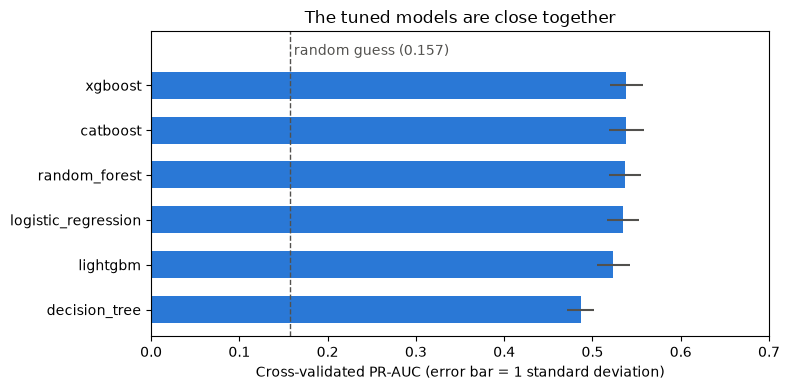

,model,pr_auc_before,pr_auc_mean,pr_auc_std,recall_mean,precision_mean,roc_auc_mean,accuracy_mean
0,xgboost,0.513,0.538,0.019,0.324,0.635,0.833,0.864
1,catboost,0.532,0.538,0.020,0.347,0.631,0.832,0.865
2,random_forest,0.529,0.537,0.018,0.262,0.674,0.828,0.864
3,logistic_regression,0.524,0.535,0.018,0.227,0.681,0.829,0.862
4,lightgbm,0.500,0.524,0.019,0.274,0.633,0.826,0.861
5,decision_tree,0.478,0.487,0.015,0.360,0.601,0.815,0.861


In [2]:
data = tuning.sort_values("pr_auc_mean")
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(data["model"], data["pr_auc_mean"], xerr=data["pr_auc_std"], color=MAIN, height=0.6, ecolor=INK)
ax.axvline(BUYER_RATE, color=INK, linestyle="--", linewidth=1)
ax.text(BUYER_RATE, len(data) - 0.4, f" random guess ({BUYER_RATE:.3f})", color=INK, va="bottom")
ax.set_ylim(-0.6, len(data) + 0.2)
ax.set_xlim(0, 0.7)
ax.set_xlabel("Cross-validated PR-AUC (error bar = 1 standard deviation)")
ax.set_title("The tuned models are close together")
plt.tight_layout()
plt.show()

tuning[["model", "pr_auc_before", "pr_auc_mean", "pr_auc_std", "recall_mean", "precision_mean", "roc_auc_mean", "accuracy_mean"]].round(3)

**Takeaway:** XGBoost and CatBoost are tied at 0.538, and Random Forest and Logistic Regression are within one standard deviation of them. Tuning added only about 0.01–0.025 PR-AUC; the Decision Tree is clearly behind. XGBoost was chosen by the rule set before tuning (highest mean PR-AUC), but CatBoost would be just as defensible. Several best settings sit at the edge of their search range (for example XGBoost `max_depth` = 2), so the models prefer to be simple and heavily regularised.

## 2. With and without PageValues

Best imbalance strategy per model, before tuning. The real model leaves PageValues out; the other column is for comparison only.

In [3]:
best = comparison.sort_values("pr_auc_mean", ascending=False).groupby(["feature_set", "model"]).head(1)
best.pivot(index="model", columns="feature_set", values="pr_auc_mean").round(3)

feature_set,with_page_values,without_page_values
model,,
catboost,0.851,0.532
decision_tree,0.807,0.478
lightgbm,0.835,0.505
logistic_regression,0.831,0.524
random_forest,0.832,0.530
xgboost,0.842,0.517


**Takeaway:** PageValues adds about 0.3 PR-AUC for every model, far more than the choice of algorithm or tuning. It is left out because it is not known mid-session (see the leakage check in `01_eda`). The dashboard will show both versions side by side.

## 3. Final model on the test set

The test split was used once, after the model and its default threshold were chosen.

In [4]:
rows = {}
for prefix, variant in final["variants"].items():
    rows[variant["name"]] = {"threshold": variant["threshold"], **variant["test_metrics"]}
print("Model type:", final["model_type"])
pd.DataFrame(rows).T

Model type: xgboost


,threshold,pr_auc,recall,precision,f1,roc_auc,accuracy
purchase_intent_v1,0.27,0.5585,0.6101,0.5287,0.5665,0.8487,0.8533
purchase_intent_with_page_values_v1,0.45,0.8674,0.8064,0.7755,0.7906,0.9723,0.9329


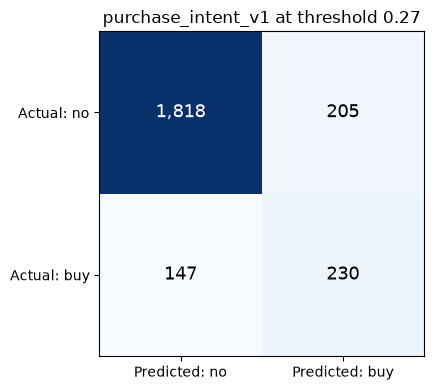

In [5]:
main = final["variants"]["purchase_intent"]
c = main["confusion"]
matrix = [[c["tn"], c["fp"]], [c["fn"], c["tp"]]]

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(matrix, cmap="Blues")
for i in range(2):
    for j in range(2):
        value = matrix[i][j]
        ax.text(j, i, f"{value:,}", ha="center", va="center", color="white" if value > 1000 else "black", fontsize=13)
ax.set_xticks([0, 1], ["Predicted: no", "Predicted: buy"])
ax.set_yticks([0, 1], ["Actual: no", "Actual: buy"])
ax.set_title(f"{main['name']} at threshold {main['threshold']:.2f}")
plt.tight_layout()
plt.show()

**Takeaway:** at the default threshold of 0.27 the model flags 435 of 2,400 test sessions (18%). It reaches 230 of the 377 buyers (recall 61%), and 53% of flagged sessions buy, against 16% of all sessions: about 3.4 times better than nudging at random. 147 buyers are missed and 205 nudges go to people who do not buy.

## 4. Precision-recall curve

Every threshold gives one point on the curve. PR-AUC is the area under it.

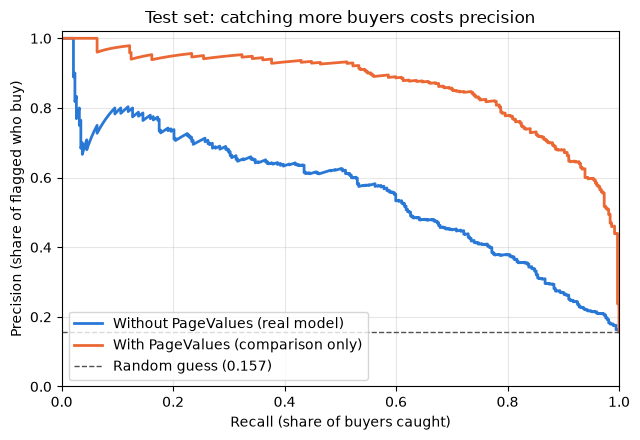

In [6]:
_, X_test, _, y_test = split_data(load_data())
probabilities = {}
for prefix, colour, label in [
    ("purchase_intent", MAIN, "Without PageValues (real model)"),
    ("purchase_intent_with_page_values", REFERENCE, "With PageValues (comparison only)"),
]:
    artifact = load_artifact(latest_version_name(settings.models_dir, prefix), settings.models_dir)
    probabilities[prefix] = artifact.pipeline.predict_proba(X_test[artifact.feature_columns])[:, 1]

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for prefix, colour, label in [
    ("purchase_intent", MAIN, "Without PageValues (real model)"),
    ("purchase_intent_with_page_values", REFERENCE, "With PageValues (comparison only)"),
]:
    precision, recall, _ = precision_recall_curve(y_test, probabilities[prefix])
    ax.plot(recall, precision, color=colour, linewidth=2, label=label)
ax.axhline(BUYER_RATE, color=INK, linestyle="--", linewidth=1, label=f"Random guess ({BUYER_RATE:.3f})")
ax.set_xlabel("Recall (share of buyers caught)")
ax.set_ylabel("Precision (share of flagged who buy)")
ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.set_title("Test set: catching more buyers costs precision")
ax.legend(loc="lower left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Takeaway:** without PageValues the curve sits well below the comparison model (test PR-AUC 0.559 vs 0.867), but it stays well above random guessing over most of the range. The gap between the two curves is the price of scoring mid-session.

## 5. Operating points: the trade-off the team chooses

A threshold decides who gets a nudge. Lower thresholds reach more buyers but also more people who would not buy. The table below is what the CRO team needs to pick one. The numbers are from the test set (2,400 sessions).

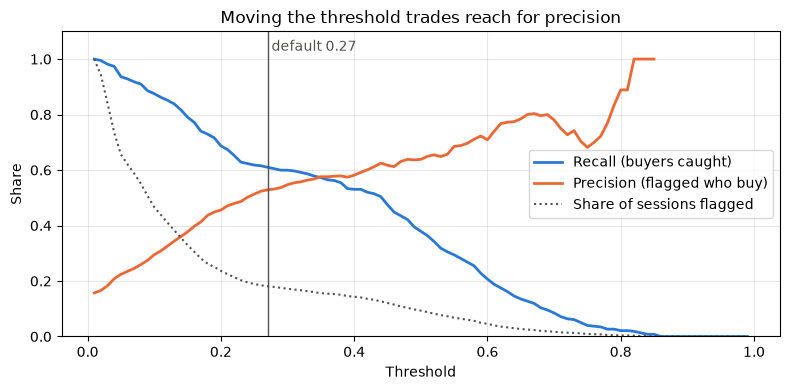

,threshold,flagged_share,precision,recall,tp,fp,fn
9,0.10,0.4662,0.2949,0.8753,330,789,47
19,0.20,0.2367,0.4560,0.6870,259,309,118
26,0.27,0.1812,0.5287,0.6101,230,205,147
29,0.30,0.1721,0.5472,0.5995,226,187,151
49,0.50,0.0933,0.6384,0.3793,143,81,234
69,0.70,0.0171,0.7805,0.0849,32,9,345


In [7]:
points = pd.read_csv(REPORTS / "operating_points_purchase_intent.csv")
default = main["threshold"]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(points["threshold"], points["recall"], color=MAIN, linewidth=2, label="Recall (buyers caught)")
# Precision is undefined when nobody is flagged, so only plot it where someone is.
anyone_flagged = points[points["tp"] + points["fp"] > 0]
ax.plot(anyone_flagged["threshold"], anyone_flagged["precision"], color=REFERENCE, linewidth=2, label="Precision (flagged who buy)")
ax.plot(points["threshold"], points["flagged_share"], color=INK, linewidth=1.5, linestyle=":", label="Share of sessions flagged")
ax.axvline(default, color=INK, linewidth=1)
ax.text(default, 1.03, f" default {default:.2f}", color=INK)
ax.set_xlabel("Threshold")
ax.set_ylabel("Share")
ax.set_ylim(0, 1.1)
ax.set_title("Moving the threshold trades reach for precision")
ax.legend(loc="center right")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

points[points["threshold"].isin([0.1, 0.2, 0.3, default, 0.5, 0.7])][["threshold", "flagged_share", "precision", "recall", "tp", "fp", "fn"]]

**How to read a row:** at threshold 0.2, `flagged_share` sessions get a nudge, `tp` of them are buyers we reach and `fp` are nudges spent on people who do not buy; `fn` buyers are missed. The default threshold maximises F1, a neutral balance of precision and recall that assumes no money values. Above about 0.7 only a few dozen sessions are flagged, so precision there jumps around.

## 6. Turning the trade-off into money (illustration)

We do not know the value of a converted session or the cost of a nudge; the team does. Once it does, `value_threshold()` picks the threshold with the best net value:

> net value = buyers reached × value per conversion − sessions nudged × cost per nudge

**The numbers below are made up, only to show how the choice moves.** Value per conversion should be the *extra* value a nudge brings, not the full order value, because many flagged buyers would have bought anyway.

In [8]:
examples = [(20, 0.5), (20, 2), (20, 5), (20, 15)]
rows = []
for value, cost in examples:
    threshold = value_threshold(points, value, cost)
    if threshold is None:
        rows.append({"value per conversion": value, "cost per nudge": cost, "best threshold": "don't nudge"})
        continue
    row = add_expected_value(points, value, cost).set_index("threshold").loc[threshold]
    rows.append({
        "value per conversion": value,
        "cost per nudge": cost,
        "best threshold": threshold,
        "sessions nudged": int(row["tp"] + row["fp"]),
        "buyers reached": int(row["tp"]),
        "net value": round(row["net_value"], 1),
    })
pd.DataFrame(rows)

,value per conversion,cost per nudge,best threshold,sessions nudged,buyers reached,net value
0,20,0.5,0.04,1761,367,6459.5
1,20,2.0,0.13,919,316,4482.0
2,20,5.0,0.31,406,225,2470.0
3,20,15.0,0.66,60,48,60.0


**Takeaway:** cheaper nudges move the best threshold down and reach more buyers. At a cost of 0.5 the best plan nudges 1,761 sessions; at 5 it nudges 406; at 15 only 60, and the net value is close to zero. A rule of thumb behind this: a group of sessions is worth nudging only if its precision is above cost ÷ value. The team enters its own numbers in the dashboard.

## 7. Limitations

- **Mid-session scoring:** the training data holds whole-session totals. Mid-visit, page counts and durations are smaller, so live results may be lower than these test scores.
- **Purchase, not persuasion:** the model predicts who will buy, not who a nudge would change. Some flagged buyers would buy anyway. Measuring the real effect of nudges needs an A/B test.
- **Probabilities:** the model was trained without class reweighting, so its probabilities are not inflated, but they have not been formally calibrated yet.
- **Model selection:** tuning and model choice used the same cross-validation folds, so the cross-validated scores are slightly optimistic. The test set gives the unbiased estimate.